# AllBirds Beacon

In [ ]:
import os
if not os.path.exists('catalog.json'):
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError:
        print('place the json files in the cwd.')

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr, pearsonr

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

In [ ]:
def load_json(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def load_table(stem):
    """Prefer parquet; fall back to jsonl lines."""
    pq, jl = Path(f'{stem}.parquet'), Path(f'{stem}.jsonl')
    if pq.exists():
        return pd.read_parquet(pq)
    if jl.exists():
        return pd.read_json(jl, lines=True)
    raise FileNotFoundError(f'Need {pq.name} or {jl.name} in cwd')

catalog = pd.DataFrame(load_json('catalog.json'))
metrics = load_table('daily_metrics')
truth   = load_table('ground_truth')

metrics['date'] = pd.to_datetime(metrics['date'])
truth['date']   = pd.to_datetime(truth['date'])

# Merge truth columns that are not already on metrics (avoid sales/stock_* collision)
truth_cols = ['date', 'sku_id', 'journey_demand', 'purchase_attempts',
              'lost_units', 'strong_oos_intents', 'availability']
df = metrics.merge(truth[truth_cols], on=['date', 'sku_id'], how='left')

print(f'catalog: {catalog.shape}')
print(f'metrics: {metrics.shape}')
print(f'truth:   {truth.shape}')
print(f'merged:  {df.shape}')
df.head()

catalog: (9300, 9)
metrics: (837000, 17)
truth:   (837000, 16)
merged:  (837000, 22)


,date,sku_id,variant_id,product_id,product_name,colour,size,subcategory,stock_start,stock_end,...,add_to_cart,add_to_wishlist,add_back_in_stock_alert,add_price_drop_alert,price,journey_demand,purchase_attempts,lost_units,strong_oos_intents,availability
0,2026-07-01,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 7,running,233,233,...,0,0,0,0,110,0,0,0,0,1.0
1,2026-07-01,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 8,running,330,330,...,2,0,0,0,110,0,0,0,0,1.0
2,2026-07-01,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 12,running,54,54,...,0,0,0,0,110,0,0,0,0,1.0
3,2026-07-01,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 13,running,164,164,...,0,4,0,2,110,0,0,0,0,1.0
4,2026-07-01,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 9,running,0,0,...,0,0,0,0,110,1,0,0,1,0.0


In [ ]:
assert df['journey_demand'].notna().all(), 'Missing ground truth rows'
assert (df['sales'] >= 0).all()
assert (df['stock_start'] >= 0).all()

print('Date range:', df['date'].min().date(), '→', df['date'].max().date())
print('Unique SKUs:', df['sku_id'].nunique())
print('Unique products:', df['product_id'].nunique())
print('Subcategories:', df['subcategory'].unique().tolist())
print('Days per SKU (mean):', df.groupby('sku_id').size().mean().round(1))


Date range: 2026-07-01 → 2026-09-28
Unique SKUs: 9300
Unique products: 817
Subcategories: ['running', 'accessories', 'shoes', 'socks', 'apparel', 'slip_on', 'sandals']
Days per SKU (mean): 90.0


## Analysis



In [ ]:
sku_stats = df.groupby(
    ['sku_id','product_id','product_name','colour','size','subcategory']
).agg(
    days_observed=('date','count'),
    total_journey_demand=('journey_demand','sum'),
    total_sales=('sales','sum'),
    total_lost_units=('lost_units','sum'),
    mean_stock=('stock_start','mean'),
    zero_stock_days=('stock_start', lambda x: (x == 0).sum()),
    mean_availability=('availability','mean'),
    total_page_views=('page_views','sum'),
    total_wishlist=('add_to_wishlist','sum'),
    total_bistock=('add_back_in_stock_alert','sum'),
    total_pricedrop=('add_price_drop_alert','sum'),
    total_cart=('add_to_cart','sum'),
).reset_index()

sku_stats['stockout_rate'] = sku_stats['zero_stock_days'] / sku_stats['days_observed']
sku_stats['lost_units_pct'] = (sku_stats['total_lost_units']
                               / sku_stats['total_journey_demand'].clip(lower=1e-6))

sku_stats.sort_values('total_journey_demand', ascending=False).head(10)


,sku_id,product_id,product_name,colour,size,subcategory,days_observed,total_journey_demand,total_sales,total_lost_units,mean_stock,zero_stock_days,mean_availability,total_page_views,total_wishlist,total_bistock,total_pricedrop,total_cart,stockout_rate,lost_units_pct
1484,P_men_s_runner_chelsea_protect_natural_black_n...,P_men_s_runner_chelsea_protect_natural_black_n...,Men's Runner Chelsea Protect - Natural Black (...,Mens Runner Chelsea Protect,UK 8,running,90,67405,9408,18692,104.533333,6,0.329253,77992,14460,8618,4339,7037,0.066667,0.277309
630,P_men_s_canvas_piper_natural_black_blizzard__m...,P_men_s_canvas_piper_natural_black_blizzard,Men's Canvas Piper - Natural Black (Blizzard),Mens Canvas Pipers Natural Black Blizzard,UK 9.5,shoes,90,13305,5792,2099,64.555556,7,0.713503,23547,4693,1234,1464,2141,0.077778,0.157760
8904,P_women_s_wool_runner_nz_medium_grey_blizzard_...,P_women_s_wool_runner_nz_medium_grey_blizzard_...,Women's Wool Runner NZ - Medium Grey (Blizzard...,Womens Wool Runner Nz Medium Grey,UK 2.5,running,90,12538,5148,3190,130.811111,32,0.609181,24659,4874,1411,1471,2185,0.355556,0.254427
7199,P_women_s_tree_glider_stony_beige_stony_cream_...,P_women_s_tree_glider_stony_beige_stony_cream_...,Women's Tree Glider - Stony Beige (Stony Cream...,Womens Tree Gliders Stony Beige Stony Cream,UK 8,shoes,90,9867,4492,2282,189.022222,27,0.663457,20619,3821,1060,1231,1987,0.300000,0.231276
7207,P_women_s_tree_glider_thunder_green_stony_crea...,P_women_s_tree_glider_thunder_green_stony_crea...,Women's Tree Glider - Thunder Green (Stony Cre...,Womens Tree Gliders Thunder Green,UK 5.5,shoes,90,5163,3502,738,351.355556,15,0.819956,13547,2738,316,859,1131,0.166667,0.142940
2751,P_men_s_tree_runner_go_stony_cream_stony_cream...,P_men_s_tree_runner_go_stony_cream_stony_cream...,Men's Tree Runner Go - Stony Cream (Stony Crea...,Mens Tree Runner Go Stony Cream,UK 7.5,running,90,4905,2733,812,243.244444,23,0.728047,10979,2174,414,677,1026,0.255556,0.165545
820,P_men_s_cruiser_jersey_light_grey_verdant_gree...,P_men_s_cruiser_jersey_light_grey_verdant_gree...,Men's Cruiser Jersey - Light Grey/Verdant Gree...,Mens Cruiser Jersey Light Grey Verdant Green,UK 11,slip_on,90,4098,1511,811,17.233333,9,0.662470,6758,1279,458,434,639,0.100000,0.197901
1652,P_men_s_runner_nz_slip_on_warm_white_warm_whit...,P_men_s_runner_nz_slip_on_warm_white_warm_whit...,Men's Runner NZ Slip On - Warm White (Warm Whi...,Mens Runner Nz Slip On Warm White,UK 7.5,running,90,2882,1637,564,110.822222,21,0.742460,6894,1339,241,433,630,0.233333,0.195697
4705,P_women_s_canvas_cruiser_slip_on_auburn_warm_w...,P_women_s_canvas_cruiser_slip_on_auburn_warm_w...,Women's Canvas Cruiser Slip On - Auburn (Warm ...,Canvas Auburn,UK 2.5,slip_on,90,2657,1267,551,58.744444,30,0.650828,5602,1076,264,353,497,0.333333,0.207377
4984,P_women_s_cruiser_canvas_anthracite_natural_wh...,P_women_s_cruiser_canvas_anthracite_natural_wh...,Women's Cruiser Canvas - Anthracite (Natural W...,Womens Cruiser Canvas Anthracite,UK 3,slip_on,90,2470,1950,259,535.122222,10,0.888444,7019,1391,111,445,644,0.111111,0.104858


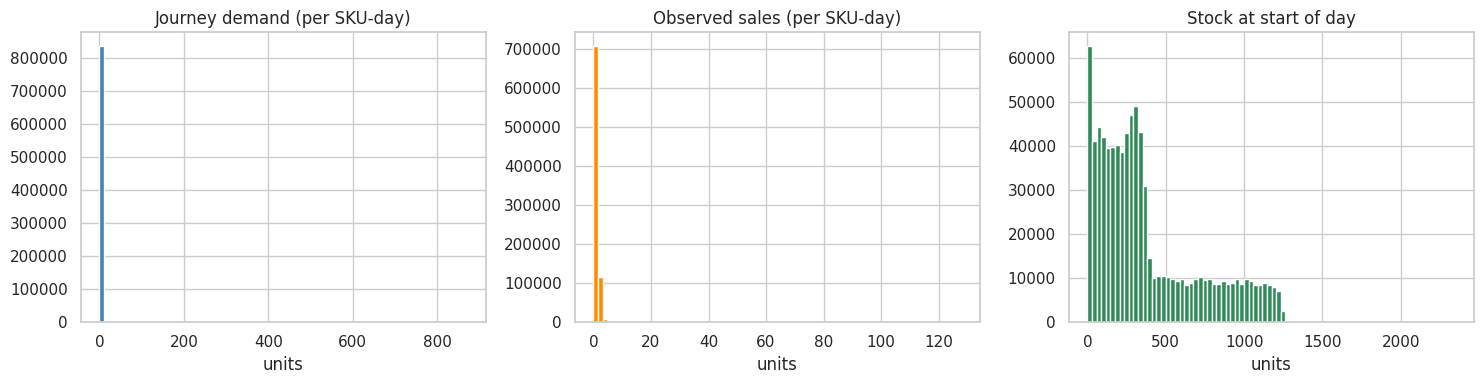

Journey demand — mean, median, p95, max: 0.89 0.0 3.0 872


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['journey_demand'], bins=80, color='steelblue')
axes[0].set_title('Journey demand (per SKU-day)')
axes[0].set_xlabel('units')
axes[1].hist(df['sales'], bins=80, color='darkorange')
axes[1].set_title('Observed sales (per SKU-day)')
axes[1].set_xlabel('units')
axes[2].hist(df['stock_start'], bins=80, color='seagreen')
axes[2].set_title('Stock at start of day')
axes[2].set_xlabel('units')
plt.tight_layout(); plt.show()

print('Journey demand — mean, median, p95, max:',
      df['journey_demand'].mean().round(2),
      df['journey_demand'].median(),
      df['journey_demand'].quantile(0.95).round(2),
      df['journey_demand'].max())


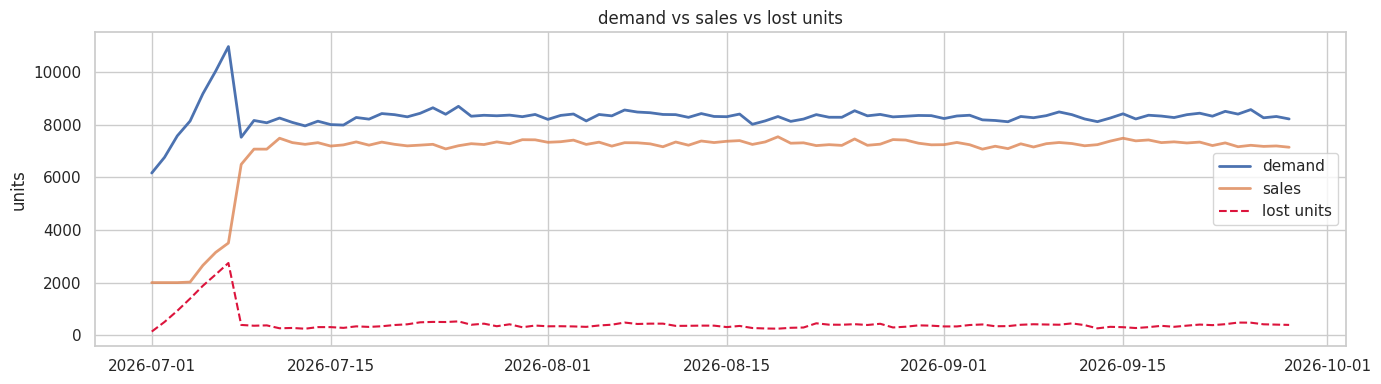

In [ ]:
daily = df.groupby('date').agg(
    demand=('journey_demand','sum'),
    sales=('sales','sum'),
    lost=('lost_units','sum'),
    pv=('page_views','sum'),
    wishlist=('add_to_wishlist','sum'),
    bistock=('add_back_in_stock_alert','sum'),
).reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily['date'], daily['demand'], label='demand', lw=2)
ax.plot(daily['date'], daily['sales'], label='sales', lw=2, alpha=0.8)
ax.plot(daily['date'], daily['lost'], label='lost units', lw=1.5,
        linestyle='--', color='crimson')
ax.set_title('demand vs sales vs lost units')
ax.set_ylabel('units')
ax.legend()
plt.tight_layout(); plt.show()


## 3. Motivation for the problem

This section quantifies the magnitude of the problem.

In [ ]:
total_demand = df['journey_demand'].sum()
total_sales  = df['sales'].sum()
total_lost   = df['lost_units'].sum()
oos_days     = (df['stock_start'] == 0).sum()
low_stock    = (df['stock_start'] < df['journey_demand']).sum()

print(f'Total demand:  {total_demand:>10,.0f} units')
print(f'Total observed sales:  {total_sales:>10,.0f} units')
print(f'Total lost units:      {total_lost:>10,.0f} ({total_lost/total_demand*100:.1f}%)')
print(f'SKU-days with zero stock:  {oos_days:,} ({oos_days/len(df)*100:.1f}%)')
print(f'SKU-days stock < demand:   {low_stock:,} ({low_stock/len(df)*100:.1f}%)')


Total demand:     748,549 units
Total observed sales:     621,486 units
Total lost units:          40,307 (5.4%)
SKU-days with zero stock:  27,941 (3.3%)
SKU-days stock < demand:   13,566 (1.6%)


## 4. Intent-Signal information content

In [ ]:
signals = ['page_views','add_to_cart','add_to_wishlist',
           'add_back_in_stock_alert','add_price_drop_alert','sales']

rows = []
for s in signals:
    r_p, _ = pearsonr(df[s], df['journey_demand'])
    r_s, _ = spearmanr(df[s], df['journey_demand'])
    rows.append({'signal': s, 'pearson': round(r_p,3), 'spearman': round(r_s,3)})
sig_corr = pd.DataFrame(rows).sort_values('spearman', ascending=False)
sig_corr


,signal,pearson,spearman
5,sales,0.689,0.959
0,page_views,0.937,0.517
1,add_to_cart,0.815,0.159
3,add_back_in_stock_alert,0.960,0.131
2,add_to_wishlist,0.839,0.088
4,add_price_drop_alert,0.778,0.076


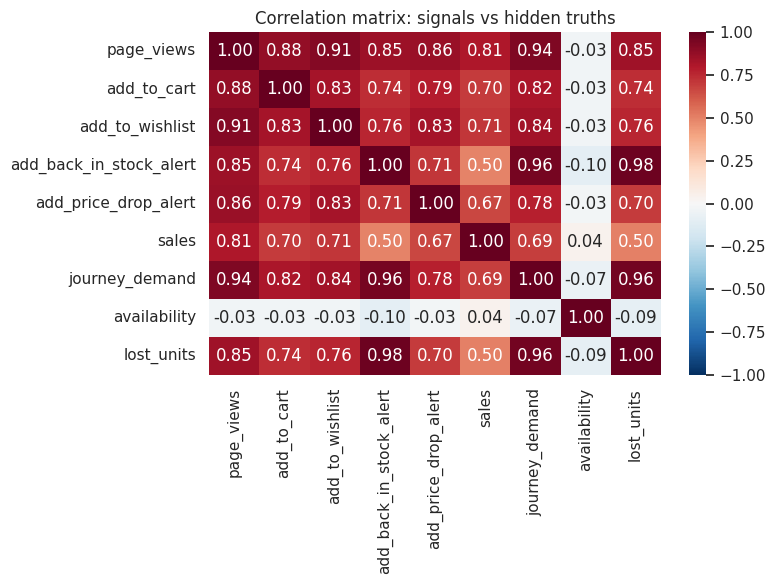

In [ ]:
corr_cols = signals + ['journey_demand','availability','lost_units']
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix: signals vs hidden truths')
plt.tight_layout(); plt.show()


## 5. Product Archetypes for Merchant Investigation

Section 11 evaluated demand estimates. This section answers a different question:
**which products require which merchant actions?**

| Set | Definition | Merchant action |
|---|---|---|
| **A — Availability Risk** | Currently unavailable AND rising external interest | Expedite restock; trigger back-in-stock notifications |
| **B — Discovery Opportunity** | High intent that catalog attributes don't adequately serve | Expand attribute coverage; targeted collection |
| **C — Needs Investigation** | High public popularity signal but unreliable commercial data | Manual review of inventory integration, content quality |

### Proxy substitutions (declared)

The synthetic dataset contains no external search logs and no public review sites.
Two substitutions are used and are declared explicitly:

- **External search interest** → proxied by the **page-view trend** (last 14 days vs prior 14 days).
- **Public reviews / social proof** → proxied by **wishlist adds, back-in-stock requests, price-drop requests**.

All three product sets are defined **only over observable data** — `ground_truth` is not used to compute membership. Ground truth is used afterwards only for sanity-checking aggregates.

In [ ]:
df = df.sort_values(['product_id', 'date']).reset_index(drop=True)

max_date     = df['date'].max()
recent_start = max_date - pd.Timedelta(days=13)
prior_end    = recent_start - pd.Timedelta(days=1)
prior_start  = prior_end - pd.Timedelta(days=13)

def _window_agg(g, s, e):
    w = g[(g['date'] >= s) & (g['date'] <= e)]
    return pd.Series({
        'pv':       w['page_views'].sum(),
        'wl':       w['add_to_wishlist'].sum(),
        'ca':       w['add_to_cart'].sum(),
        'bi':       w['add_back_in_stock_alert'].sum(),
        'pdalert':  w['add_price_drop_alert'].sum(),
        'sales':    w['sales'].sum(),
        'demand':   w['journey_demand'].sum(),
        'lost':     w['lost_units'].sum(),
        'stockout': (w['stock_start'] == 0).mean(),
        'avail':    w['availability'].mean(),
    })

recent = df.groupby('product_id').apply(
    lambda g: _window_agg(g, recent_start, max_date)
).add_prefix('r_')
prior  = df.groupby('product_id').apply(
    lambda g: _window_agg(g, prior_start, prior_end)
).add_prefix('p_')

base = (df.groupby('product_id')
          .agg(product_name=('product_name','first'),
               subcategory=('subcategory','first'),
               n_skus=('sku_id','nunique'),
               n_colours=('colour','nunique'))
          .reset_index())

cat_avail = (catalog.groupby('product_id')['available_in_scrape']
                    .mean().rename('catalog_avail_ratio'))
base = base.merge(cat_avail, on='product_id', how='left')
base['catalog_size_gap'] = 1 - base['catalog_avail_ratio'].fillna(0)

prod = (base.merge(recent, left_on='product_id', right_index=True)
            .merge(prior,  left_on='product_id', right_index=True))

prod['pv_trend']        = ((prod['r_pv'] - prod['p_pv'])
                           / prod['p_pv'].clip(lower=1))
prod['intent_recent']   = prod['r_wl'] + prod['r_ca'] + prod['r_pdalert']
prod['intent_prior']    = prod['p_wl'] + prod['p_ca'] + prod['p_pdalert']
prod['intent_trend']    = ((prod['intent_recent'] - prod['intent_prior'])
                           / prod['intent_prior'].clip(lower=1))
prod['intent_to_sales'] = prod['intent_recent'] / prod['r_sales'].clip(lower=1)
prod['wl_per_view']     = prod['r_wl'] / prod['r_pv'].clip(lower=1)
prod['cart_per_view']   = prod['r_ca'] / prod['r_pv'].clip(lower=1)
prod['bistock_density'] = prod['r_bi'] / prod['r_demand'].clip(lower=1)

print(f'Products:      {len(prod)}')
print(f'Recent window: {recent_start.date()} → {max_date.date()}')
print(f'Prior window:  {prior_start.date()} → {prior_end.date()}')
prod[['product_name','r_pv','pv_trend','r_stockout',
      'catalog_size_gap','r_wl','r_sales']].head(8).round(3)


Products:      817
Recent window: 2026-09-15 → 2026-09-28
Prior window:  2026-09-01 → 2026-09-14


,product_name,r_pv,pv_trend,r_stockout,catalog_size_gap,r_wl,r_sales
0,54,216.0,-0.053,0.0,0.143,46.0,77.0
1,Allbirds Laces - Blizzard - Flat,74.0,0.451,0.0,0.000,20.0,27.0
2,Allbirds Laces - Blizzard - Round,81.0,1.189,0.0,0.000,10.0,24.0
3,Allbirds Laces - Dark Navy - Flat,60.0,0.053,0.0,0.000,16.0,19.0
4,Allbirds Laces - Dark Navy - Round,59.0,0.157,0.0,0.000,23.0,12.0
5,Allbirds Laces - Natural Grey Heather - Flat,57.0,-0.017,0.0,0.000,7.0,18.0
6,Allbirds Laces - Natural Grey Heather - Round,63.0,-0.074,0.0,0.000,9.0,23.0
7,Allbirds Laces - True Black - Flat,44.0,-0.254,0.0,0.000,14.0,18.0


In [ ]:
# Product A — Availability Risk ----
STOCKOUT_THRESHOLD = 0.50
TREND_THRESHOLD    = 0.10

mask_a = ((prod['r_stockout'] >= STOCKOUT_THRESHOLD)
          & (prod['pv_trend'] >= TREND_THRESHOLD))

prod['A_availability_risk'] = mask_a
prod['A_score'] = (np.log1p(prod['r_lost'].clip(lower=0))
                   * prod['r_stockout']
                   * (1 + prod['pv_trend'].clip(lower=0)))

product_a = (prod[mask_a]
             .sort_values('A_score', ascending=False)
             .reset_index(drop=True))

print(f'Product A — Availability Risk:  {len(product_a)} items')
cols_a = ['product_name','subcategory','r_stockout','pv_trend',
          'r_lost','catalog_size_gap','r_bi','A_score']
product_a[cols_a].head(15).round(3)

Product A — Availability Risk:  0 items


,product_name,subcategory,r_stockout,pv_trend,r_lost,catalog_size_gap,r_bi,A_score


In [ ]:
# Product B — Discovery Opportunity ----
high_intent = prod['r_pv'] > prod['r_pv'].quantile(0.75)
poor_fit    = ((prod['catalog_size_gap'] > 0.30)
               | (prod['cart_per_view'] < prod['cart_per_view'].median() * 0.5))

mask_b = high_intent & poor_fit

prod['B_discovery_opportunity'] = mask_b
prod['B_score'] = (np.log1p(prod['r_pv'])
                   * (1 + prod['catalog_size_gap'].clip(lower=0))
                   * (1 + prod['intent_trend'].clip(lower=0)))

product_b = (prod[mask_b]
             .sort_values('B_score', ascending=False)
             .reset_index(drop=True))

print(f'Product B — Discovery Opportunity: {len(product_b)} items')
cols_b = ['product_name','subcategory','r_pv','cart_per_view',
          'catalog_size_gap','intent_trend','r_wl','B_score']
product_b[cols_b].head(15).round(3)

Product B — Discovery Opportunity: 107 items


,product_name,subcategory,r_pv,cart_per_view,catalog_size_gap,intent_trend,r_wl,B_score
0,Women's Tree Runner Go - Medium Grey (Blizzard...,running,519.0,0.118,1.000,0.477,102.0,18.477
1,Men's Canvas Piper - Natural Black (Blizzard),shoes,4943.0,0.086,1.000,0.056,947.0,17.968
2,Women's Canvas Cruiser Slip On - Auburn (Warm ...,slip_on,1235.0,0.093,1.000,0.251,271.0,17.818
3,Men's Tree Runner Go - Hazy Pine (Natural Whit...,running,493.0,0.077,1.000,0.283,100.0,15.921
4,Men's Tree Runner Go - Stony Cream (Stony Crea...,running,2234.0,0.095,1.000,-0.093,423.0,15.424
5,Men's Canvas Cruiser Slip On - Blizzard (Blizz...,slip_on,869.0,0.099,0.962,0.146,181.0,15.214
6,Women's Tree Glider - Blizzard/Basin Pink (Bli...,shoes,925.0,0.095,0.769,0.258,199.0,15.203
7,Men's Canvas Cruiser Slip On - Deep Navy Strip...,slip_on,769.0,0.087,1.000,0.127,175.0,14.986
8,Men's Canvas Cruiser Slip On - Auburn (Warm Wh...,slip_on,785.0,0.094,1.000,0.089,153.0,14.526
9,Men's Canvas Cruiser Slip On - Warm White (Nat...,slip_on,923.0,0.098,1.000,0.057,196.0,14.438


In [ ]:
# Product C — Needs Investigation ----
high_popularity = (
    (prod['r_wl']      > prod['r_wl'].quantile(0.75)) |
    (prod['r_bi']      > prod['r_bi'].quantile(0.75)) |
    (prod['r_pdalert'] > prod['r_pdalert'].quantile(0.75))
)
low_sales       = prod['r_sales'] < prod['r_sales'].median()
ambiguous_stock = prod['r_stockout'].between(0.20, 0.80)

mask_c = high_popularity & (low_sales | ambiguous_stock)

prod['C_needs_investigation'] = mask_c
prod['C_score'] = (np.log1p(prod['r_wl'] + prod['r_bi'] + prod['r_pdalert'])
                   * (1 + prod['intent_to_sales'].clip(upper=50)))

product_c = (prod[mask_c]
             .sort_values('C_score', ascending=False)
             .reset_index(drop=True))

print(f'Product C — Needs Investigation: {len(product_c)} items')
cols_c = ['product_name','subcategory','r_wl','r_bi','r_sales',
          'r_stockout','intent_to_sales','C_score']
product_c[cols_c].head(15).round(3)

Product C — Needs Investigation: 17 items


,product_name,subcategory,r_wl,r_bi,r_sales,r_stockout,intent_to_sales,C_score
0,Men's Runner NZ Slip On - Anthracite (Dark Ant...,running,103.0,0.0,114.0,0.0,1.535,12.473
1,Women's Wool Runner NZ - Rugged Beige (Rugged ...,running,96.0,0.0,109.0,0.0,1.505,12.191
2,Women's Breezer Mary Jane - Dusty Pink (Dusty ...,shoes,93.0,0.0,110.0,0.0,1.409,11.612
3,Men's Strider Explore - Hazy Burgundy (Weather...,shoes,94.0,0.0,114.0,0.0,1.421,11.611
4,Women's Tree Glider - Deep Navy (Blizzard Sole),shoes,80.0,0.0,101.0,0.0,1.455,11.586
5,Men's Wool Dasher Mizzle - Natural Black (Natu...,shoes,87.0,0.0,109.0,0.0,1.376,11.415
6,Women's Cruiser Corduroy - Dark Navy (Stony Cr...,slip_on,90.0,0.0,116.0,0.0,1.371,11.330
7,Women's Cruiser - Natural White (Natural White...,slip_on,82.0,0.0,104.0,0.0,1.356,11.157
8,Men's Wool Strider - Rugged Beige (Natural Whi...,shoes,86.0,0.0,107.0,0.0,1.318,11.057
9,Men's Wool Runner NZ Mid Waterproof - Natural ...,running,70.0,0.0,106.0,0.0,1.340,10.844


In [ ]:
# Consolidated merchant action list ----
action_summary = pd.DataFrame({
    'Product set': [
        'A — Availability Risk',
        'B — Discovery Opportunity',
        'C — Needs Investigation',
    ],
    'Count': [len(product_a), len(product_b), len(product_c)],
    'Recommended merchant action': [
        'Expedite restock; trigger back-in-stock notifications; consider price protection',
        'Expand catalog attributes (sizes, colours); launch a targeted collection page',
        'Manual review of inventory integration, content quality, review authenticity',
    ],
})
action_summary

,Product set,Count,Recommended merchant action
0,A — Availability Risk,0,Expedite restock; trigger back-in-stock notifi...
1,B — Discovery Opportunity,107,"Expand catalog attributes (sizes, colours); la..."
2,C — Needs Investigation,17,"Manual review of inventory integration, conten..."


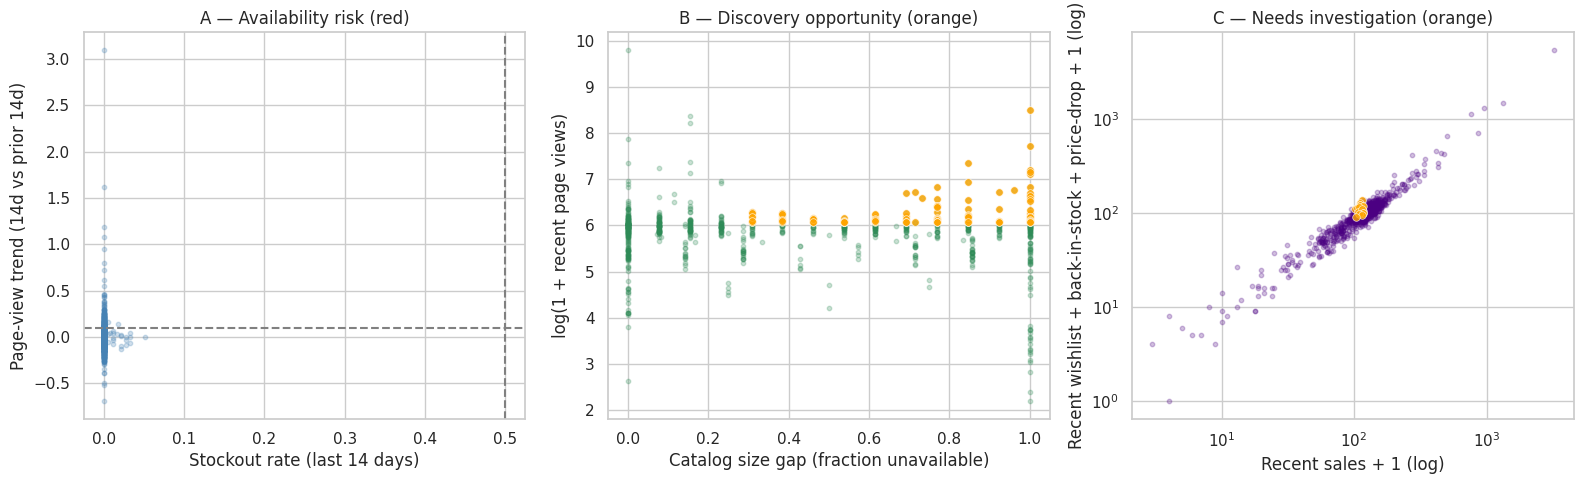

In [ ]:
# Visualise the three sets ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(prod['r_stockout'], prod['pv_trend'],
                alpha=0.25, s=10, color='steelblue')
axes[0].scatter(product_a['r_stockout'], product_a['pv_trend'],
                alpha=0.8, s=30, color='crimson',
                edgecolor='white', linewidth=0.5)
axes[0].axhline(TREND_THRESHOLD,    ls='--', color='grey')
axes[0].axvline(STOCKOUT_THRESHOLD, ls='--', color='grey')
axes[0].set_xlabel('Stockout rate (last 14 days)')
axes[0].set_ylabel('Page-view trend (14d vs prior 14d)')
axes[0].set_title('A — Availability risk (red)')

axes[1].scatter(prod['catalog_size_gap'], np.log1p(prod['r_pv']),
                alpha=0.25, s=10, color='seagreen')
axes[1].scatter(product_b['catalog_size_gap'], np.log1p(product_b['r_pv']),
                alpha=0.8, s=30, color='orange',
                edgecolor='white', linewidth=0.5)
axes[1].set_xlabel('Catalog size gap (fraction unavailable)')
axes[1].set_ylabel('log(1 + recent page views)')
axes[1].set_title('B — Discovery opportunity (orange)')

x_all = prod['r_sales'] + 1
y_all = prod['r_wl'] + prod['r_bi'] + prod['r_pdalert'] + 1
x_c   = product_c['r_sales'] + 1
y_c   = product_c['r_wl'] + product_c['r_bi'] + product_c['r_pdalert'] + 1
axes[2].scatter(x_all, y_all, alpha=0.25, s=10, color='indigo')
axes[2].scatter(x_c, y_c, alpha=0.8, s=30, color='orange',
                edgecolor='white', linewidth=0.5)
axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_xlabel('Recent sales + 1 (log)')
axes[2].set_ylabel('Recent wishlist + back-in-stock + price-drop + 1 (log)')
axes[2].set_title('C — Needs investigation (orange)')

plt.tight_layout(); plt.show()